# Initial Training

In [ ]:
torch.cuda.empty_cache()

## 1. Setup & imports

In [ ]:
# Uncomment to install dependencies
# !pip install torch nibabel numpy matplotlib

import os
import glob
import random
import time

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt

try:
    import nibabel as nib
except ImportError as e:
    raise ImportError("Run `pip install nibabel` to read .nii.gz files.") from e

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")

Using device: cuda


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
DATA_ROOT = "/content/drive/MyDrive/BraTS/brats20-dataset/1/BraTS2020_TrainingData/MICCAI_BraTS2020_TrainingData" # <-- Please update this path to the correct location of your BraTS2020 dataset
OUT_DIR = "./checkpoints"
os.makedirs(OUT_DIR, exist_ok=True)

PATCH_SIZE = (128, 128, 128)
BASE_CH = 16
DEPTH = 4
NUM_CLASSES = 4
BATCH_SIZE = 4
EPOCHS = 6
LR = 1e-4
WEIGHT_DECAY = 1e-5
VAL_FRACTION = 0.2
NUM_WORKERS = 4
DEEP_SUPERVISION = True
USE_AMP = True
VAL_EVERY = 5
SEED = 42

torch.manual_seed(SEED)
random.seed(SEED)
np.random.seed(SEED)

## 2. Dataset




In [ ]:
MODALITIES = ("flair", "t1", "t1ce", "t2")


def load_nifti(path):
    return nib.load(path).get_fdata(dtype=np.float32)


def zscore_normalize(volume, mask=None):
    """Normalize a modality volume to zero mean / unit variance over the brain (nonzero) region."""
    if mask is None:
        mask = volume > 0
    if mask.sum() == 0:
        return volume
    mean = volume[mask].mean()
    std = volume[mask].std() + 1e-8
    out = volume.copy()
    out[mask] = (volume[mask] - mean) / std
    return out


def remap_labels(seg):
    """BraTS label 4 (ET) -> 3, so classes are {0,1,2,3}."""
    seg = seg.copy()
    seg[seg == 4] = 3
    return seg

In [ ]:
class BraTS2020Dataset(Dataset):
    """
    Loads BraTS2020 subject folders, stacks the 4 modalities into a
    (4, D, H, W) tensor, and returns random 3D patches for training or
    full volumes for validation/inference.
    """

    def __init__(self, root_dir, subject_ids=None, patch_size=(128, 128, 128),
                 train=True, modalities=MODALITIES, foreground_oversample_prob=0.8):
        self.root_dir = root_dir
        self.patch_size = patch_size
        self.train = train
        self.modalities = modalities
        self.foreground_oversample_prob = foreground_oversample_prob

        if subject_ids is None:
            # NOTE: list_valid_subjects is defined in the next cell; if you use this
            # class before that cell has run, pass subject_ids explicitly instead.
            subject_ids = list_valid_subjects(root_dir, modalities=modalities, require_seg=True)
        self.subject_ids = subject_ids

    def __len__(self):
        return len(self.subject_ids)

    def _subject_paths(self, subject_id):
        subj_dir = os.path.join(self.root_dir, subject_id)

        def resolve(base):
            if os.path.exists(base + ".nii.gz"):
                return base + ".nii.gz"
            elif os.path.exists(base + ".nii"):
                return base + ".nii"
            else:
                raise FileNotFoundError(f"No .nii or .nii.gz found for {base}")

        paths = {m: resolve(os.path.join(subj_dir, f"{subject_id}_{m}")) for m in self.modalities}
        paths["seg"] = resolve(os.path.join(subj_dir, f"{subject_id}_seg"))
        return paths

    def _load_subject(self, subject_id):
        paths = self._subject_paths(subject_id)
        vols = [load_nifti(paths[m]) for m in self.modalities]
        brain_mask = vols[0] > 0
        vols = [zscore_normalize(v, brain_mask) for v in vols]
        image = np.stack(vols, axis=0)  # (C, D, H, W)

        if os.path.exists(paths["seg"]):
            seg = load_nifti(paths["seg"]).astype(np.int64)
            seg = remap_labels(seg)
        else:
            seg = np.zeros(image.shape[1:], dtype=np.int64)

        return image, seg

    @staticmethod
    def _pad_to_at_least(image, seg, target_shape):
        pads = []
        cur_shape = image.shape[1:]
        for c, t in zip(cur_shape, target_shape):
            diff = max(t - c, 0)
            pads.append((diff // 2, diff - diff // 2))
        image = np.pad(image, ((0, 0), *pads), mode="constant", constant_values=0)
        seg = np.pad(seg, pads, mode="constant", constant_values=0)
        return image, seg

    def _random_crop(self, image, seg):
        pd, ph, pw = self.patch_size
        image, seg = self._pad_to_at_least(image, seg, self.patch_size)
        _, D, H, W = image.shape

        use_foreground = random.random() < self.foreground_oversample_prob and seg.max() > 0

        if use_foreground:
            fg_voxels = np.argwhere(seg > 0)
            cz, cy, cx = fg_voxels[random.randrange(len(fg_voxels))]
        else:
            cz, cy, cx = random.randrange(D), random.randrange(H), random.randrange(W)

        z0 = int(np.clip(cz - pd // 2, 0, max(D - pd, 0)))
        y0 = int(np.clip(cy - ph // 2, 0, max(H - ph, 0)))
        x0 = int(np.clip(cx - pw // 2, 0, max(W - pw, 0)))

        image = image[:, z0:z0 + pd, y0:y0 + ph, x0:x0 + pw]
        seg = seg[z0:z0 + pd, y0:y0 + ph, x0:x0 + pw]
        return image, seg

    @staticmethod
    def _random_flip(image, seg):
        for axis in (1, 2, 3):  # D, H, W (channel axis = 0)
            if random.random() < 0.5:
                image = np.flip(image, axis=axis).copy()
                seg = np.flip(seg, axis=axis - 1).copy()
        return image, seg

    def __getitem__(self, idx):
        subject_id = self.subject_ids[idx]
        image, seg = self._load_subject(subject_id)

        if self.train:
            if self.patch_size is not None:
                image, seg = self._random_crop(image, seg)
            image, seg = self._random_flip(image, seg)

        image_t = torch.from_numpy(image).float()
        seg_t = torch.from_numpy(seg).long()
        return {"image": image_t, "label": seg_t, "subject_id": subject_id}

In [ ]:
def _exists_nii(base):
    return os.path.exists(base + ".nii.gz") or os.path.exists(base + ".nii")


def _subject_is_complete(subj_dir, subject_id, modalities=MODALITIES, require_seg=True):
    """Check that every modality (and optionally the seg mask) exists for a subject."""
    ok = all(_exists_nii(os.path.join(subj_dir, f"{subject_id}_{m}")) for m in modalities)
    if require_seg:
        ok = ok and _exists_nii(os.path.join(subj_dir, f"{subject_id}_seg"))
    return ok


def list_valid_subjects(root_dir, modalities=MODALITIES, require_seg=True):
    """Scan root_dir for subject folders and keep only the ones with all required files.

    BraTS2020 mirrors sometimes ship a subject with a missing/renamed file
    (e.g. BraTS20_Training_355's segmentation is absent on some mirrors). Filtering
    here avoids a FileNotFoundError crashing training mid-epoch inside a DataLoader
    worker.
    """
    all_ids = sorted([
        os.path.basename(p) for p in glob.glob(os.path.join(root_dir, "*"))
        if os.path.isdir(p)
    ])
    valid, skipped = [], []
    for sid in all_ids:
        subj_dir = os.path.join(root_dir, sid)
        if _subject_is_complete(subj_dir, sid, modalities, require_seg):
            valid.append(sid)
        else:
            skipped.append(sid)
    if skipped:
        print(f"Skipping {len(skipped)} subject(s) with missing files: {skipped}")
    return valid


def make_train_val_split(root_dir, val_fraction=0.2, seed=42, modalities=MODALITIES):
    """Build a reproducible train/val split from the *valid* subjects under root_dir."""
    subject_ids = list_valid_subjects(root_dir, modalities=modalities, require_seg=True)
    if len(subject_ids) == 0:
        raise RuntimeError(f"No complete subjects found under {root_dir}")

    rng = random.Random(seed)
    ids = subject_ids[:]
    rng.shuffle(ids)

    n_val = max(1, int(len(ids) * val_fraction))
    val_ids = sorted(ids[:n_val])
    train_ids = sorted(ids[n_val:])
    return train_ids, val_ids


In [ ]:
# Build train/val splits and datasets
#%%script false --no-raise-error
train_ids, val_ids = make_train_val_split(DATA_ROOT, VAL_FRACTION, SEED)
print(f"Train subjects: {len(train_ids)}, Val subjects: {len(val_ids)}")

train_ds = BraTS2020Dataset(DATA_ROOT, subject_ids=train_ids, patch_size=PATCH_SIZE, train=True)
val_ds = BraTS2020Dataset(DATA_ROOT, subject_ids=val_ids, patch_size=None, train=False)

train_loader = DataLoader(
    train_ds, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=NUM_WORKERS, pin_memory=True, drop_last=True,
)

Skipping 1 subject(s) with missing files: ['BraTS20_Training_355']
Train subjects: 295, Val subjects: 73


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:424: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


## 3. Model — 3D Attention U-Net




In [ ]:
def conv_block(in_ch, out_ch, num_groups=8):
    """Two 3x3x3 conv layers, each followed by GroupNorm + ReLU."""
    return nn.Sequential(
        nn.Conv3d(in_ch, out_ch, kernel_size=3, padding=1, bias=False),
        nn.GroupNorm(num_groups=min(num_groups, out_ch), num_channels=out_ch),
        nn.ReLU(inplace=True),
        nn.Conv3d(out_ch, out_ch, kernel_size=3, padding=1, bias=False),
        nn.GroupNorm(num_groups=min(num_groups, out_ch), num_channels=out_ch),
        nn.ReLU(inplace=True),
    )


class DownBlock(nn.Module):
    """Encoder stage: conv_block followed by max-pool downsampling."""

    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.conv = conv_block(in_ch, out_ch)
        self.pool = nn.MaxPool3d(kernel_size=2, stride=2)

    def forward(self, x):
        skip = self.conv(x)
        down = self.pool(skip)
        return skip, down

In [ ]:
class AttentionGate3D(nn.Module):
    """
    Additive attention gate (Oktay et al., 2018) adapted to 3D.

    g: gating signal from the coarser decoder level (query)
    x: skip connection features from the encoder (to be filtered)

    Produces an attention coefficient map in [0, 1] that re-weights x before
    it is concatenated with the upsampled decoder features.
    """

    def __init__(self, gate_ch, skip_ch, inter_ch):
        super().__init__()
        self.W_g = nn.Sequential(
            nn.Conv3d(gate_ch, inter_ch, kernel_size=1, stride=1, padding=0, bias=True),
            nn.GroupNorm(min(8, inter_ch), inter_ch),
        )
        self.W_x = nn.Sequential(
            nn.Conv3d(skip_ch, inter_ch, kernel_size=1, stride=1, padding=0, bias=True),
            nn.GroupNorm(min(8, inter_ch), inter_ch),
        )
        self.psi = nn.Sequential(
            nn.Conv3d(inter_ch, 1, kernel_size=1, stride=1, padding=0, bias=True),
            nn.GroupNorm(1, 1),
            nn.Sigmoid(),
        )
        self.relu = nn.ReLU(inplace=True)

    def forward(self, g, x):
        if g.shape[2:] != x.shape[2:]:
            g = F.interpolate(g, size=x.shape[2:], mode="trilinear", align_corners=False)
        g1 = self.W_g(g)
        x1 = self.W_x(x)
        psi = self.relu(g1 + x1)
        alpha = self.psi(psi)  # attention coefficients, shape (B,1,D,H,W)
        return x * alpha       # gated skip connection


class UpBlock(nn.Module):
    """Decoder stage: upsample, attention-gate the skip, concat, conv_block."""

    def __init__(self, in_ch, skip_ch, out_ch, trilinear=False):
        super().__init__()
        if trilinear:
            self.up = nn.Sequential(
                nn.Upsample(scale_factor=2, mode="trilinear", align_corners=False),
                nn.Conv3d(in_ch, in_ch, kernel_size=1),
            )
        else:
            self.up = nn.ConvTranspose3d(in_ch, in_ch, kernel_size=2, stride=2)

        self.attn = AttentionGate3D(gate_ch=in_ch, skip_ch=skip_ch, inter_ch=max(skip_ch // 2, 1))
        self.conv = conv_block(in_ch + skip_ch, out_ch)

    def forward(self, x, skip):
        x = self.up(x)
        if x.shape[2:] != skip.shape[2:]:
            x = F.interpolate(x, size=skip.shape[2:], mode="trilinear", align_corners=False)
        gated_skip = self.attn(g=x, x=skip)
        x = torch.cat([gated_skip, x], dim=1)
        return self.conv(x)

In [ ]:
class AttentionUNet3D(nn.Module):
    """
    3D Attention U-Net.

    in_channels:  number of input MRI modalities (4 -> FLAIR, T1, T1ce, T2)
    out_channels: number of output classes (4 -> BG/NCR-NET/ED/ET)
    base_ch:      number of feature maps at the first encoder level
    depth:        number of down/up-sampling stages
    deep_supervision: also return auxiliary outputs from intermediate decoder levels
    """

    def __init__(self, in_channels=4, out_channels=4, base_ch=16, depth=4,
                 trilinear=False, deep_supervision=False):
        super().__init__()
        self.depth = depth
        self.deep_supervision = deep_supervision

        chs = [base_ch * (2 ** i) for i in range(depth + 1)]

        self.down_blocks = nn.ModuleList()
        prev_ch = in_channels
        for i in range(depth):
            self.down_blocks.append(DownBlock(prev_ch, chs[i]))
            prev_ch = chs[i]

        self.bottleneck = conv_block(chs[depth - 1], chs[depth])

        self.up_blocks = nn.ModuleList()
        prev_ch = chs[depth]
        for i in reversed(range(depth)):
            self.up_blocks.append(UpBlock(prev_ch, chs[i], chs[i], trilinear=trilinear))
            prev_ch = chs[i]

        self.out_conv = nn.Conv3d(chs[0], out_channels, kernel_size=1)

        if deep_supervision:
            # up_blocks[0] outputs chs[depth-1] channels, up_blocks[1] outputs chs[depth-2], etc.
            self.aux_heads = nn.ModuleList([
                nn.Conv3d(chs[depth - 1 - i], out_channels, kernel_size=1)
                for i in range(min(2, depth))
            ])

        self._init_weights()

    def _init_weights(self):
        for m in self.modules():
            if isinstance(m, (nn.Conv3d, nn.ConvTranspose3d)):
                nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")
                if m.bias is not None:
                    nn.init.zeros_(m.bias)
            elif isinstance(m, nn.GroupNorm):
                nn.init.ones_(m.weight)
                nn.init.zeros_(m.bias)

    def forward(self, x):
        skips = []
        for down in self.down_blocks:
            skip, x = down(x)
            skips.append(skip)

        x = self.bottleneck(x)

        aux_outputs = []
        for i, up in enumerate(self.up_blocks):
            x = up(x, skips[-(i + 1)])
            if self.deep_supervision and i < len(getattr(self, "aux_heads", [])):
                aux_outputs.append(self.aux_heads[i](x))

        logits = self.out_conv(x)

        if self.deep_supervision and len(aux_outputs) > 0:
            aux_outputs = [
                F.interpolate(a, size=logits.shape[2:], mode="trilinear", align_corners=False)
                for a in aux_outputs
            ]
            return logits, aux_outputs
        return logits

Quick shape/parameter-count sanity check:

In [ ]:
_test_model = AttentionUNet3D(in_channels=4, out_channels=NUM_CLASSES, base_ch=BASE_CH, depth=DEPTH)
_x = torch.randn(1, 4, 64, 64, 64)
with torch.no_grad():
    _y = _test_model(_x)
print("Input:", _x.shape, "Output:", _y.shape)
n_params = sum(p.numel() for p in _test_model.parameters())
print(f"Trainable parameters: {n_params/1e6:.2f}M")
del _test_model, _x, _y

Input: torch.Size([1, 4, 64, 64, 64]) Output: torch.Size([1, 4, 64, 64, 64])
Trainable parameters: 6.62M


## 4. Losses & metrics





In [ ]:
class DiceLoss(nn.Module):
    def __init__(self, num_classes, smooth=1e-5, ignore_background=False):
        super().__init__()
        self.num_classes = num_classes
        self.smooth = smooth
        self.ignore_background = ignore_background

    def forward(self, logits, target):
        probs = F.softmax(logits, dim=1)
        target_onehot = F.one_hot(target, num_classes=self.num_classes)
        target_onehot = target_onehot.permute(0, 4, 1, 2, 3).float()

        dims = (0, 2, 3, 4)
        intersection = torch.sum(probs * target_onehot, dims)
        cardinality = torch.sum(probs + target_onehot, dims)
        dice_per_class = (2.0 * intersection + self.smooth) / (cardinality + self.smooth)

        if self.ignore_background:
            dice_per_class = dice_per_class[1:]

        return 1.0 - dice_per_class.mean()


class DiceCELoss(nn.Module):
    def __init__(self, num_classes, ce_weight=None, dice_weight=1.0, ce_weight_scale=1.0):
        super().__init__()
        self.dice = DiceLoss(num_classes)
        self.ce = nn.CrossEntropyLoss(weight=ce_weight)
        self.dice_weight = dice_weight
        self.ce_weight_scale = ce_weight_scale

    def forward(self, logits, target):
        return self.dice_weight * self.dice(logits, target) + self.ce_weight_scale * self.ce(logits, target)


class DeepSupervisionLoss(nn.Module):
    """Applies the base loss to auxiliary decoder outputs too, with decreasing weight."""

    def __init__(self, base_loss, aux_weights=(0.5, 0.25)):
        super().__init__()
        self.base_loss = base_loss
        self.aux_weights = aux_weights

    def forward(self, output, target):
        if isinstance(output, tuple):
            main_logits, aux_logits_list = output
            loss = self.base_loss(main_logits, target)
            for w, aux_logits in zip(self.aux_weights, aux_logits_list):
                loss = loss + w * self.base_loss(aux_logits, target)
            return loss
        return self.base_loss(output, target)

In [ ]:
@torch.no_grad()
def brats_region_dice(logits, target, smooth=1e-5):
    """
    Dice for the 3 clinically-reported BraTS regions (labels remapped to {0,1,2,3}):
        WT (whole tumor) = labels {1,2,3};  TC (tumor core) = labels {1,3};  ET = label {3}
    """
    preds = torch.argmax(logits, dim=1)

    def region_dice(pred_mask, target_mask):
        pred_mask, target_mask = pred_mask.float(), target_mask.float()
        intersection = (pred_mask * target_mask).sum()
        union = pred_mask.sum() + target_mask.sum()
        return ((2.0 * intersection + smooth) / (union + smooth)).item()

    wt_pred, wt_tgt = (preds > 0), (target > 0)
    tc_pred, tc_tgt = ((preds == 1) | (preds == 3)), ((target == 1) | (target == 3))
    et_pred, et_tgt = (preds == 3), (target == 3)

    return {
        "WT": region_dice(wt_pred, wt_tgt),
        "TC": region_dice(tc_pred, tc_tgt),
        "ET": region_dice(et_pred, et_tgt),
    }

## 5. Sliding-window inference

Full BraTS volumes (155×240×240) are too large to fit in one forward pass at
training-time patch sizes, so validation/inference tile the volume into
overlapping patches and average logits in the overlap regions.


In [ ]:
def sliding_window_inference(model, image, patch_size, num_classes, overlap=0.5, device="cuda"):
    """image: (C, D, H, W) tensor for a single subject (no batch dim)."""
    C, D, H, W = image.shape
    pd, ph, pw = patch_size

    pad_d, pad_h, pad_w = max(pd - D, 0), max(ph - H, 0), max(pw - W, 0)
    image_p = F.pad(image.unsqueeze(0), (0, pad_w, 0, pad_h, 0, pad_d), mode="constant", value=0)[0]
    _, Dp, Hp, Wp = image_p.shape

    stride_d = max(int(pd * (1 - overlap)), 1)
    stride_h = max(int(ph * (1 - overlap)), 1)
    stride_w = max(int(pw * (1 - overlap)), 1)

    logits_sum = torch.zeros((num_classes, Dp, Hp, Wp), device=device)
    counts = torch.zeros((1, Dp, Hp, Wp), device=device)

    z_starts = list(range(0, max(Dp - pd, 0) + 1, stride_d)) or [0]
    y_starts = list(range(0, max(Hp - ph, 0) + 1, stride_h)) or [0]
    x_starts = list(range(0, max(Wp - pw, 0) + 1, stride_w)) or [0]
    if z_starts[-1] != Dp - pd:
        z_starts.append(max(Dp - pd, 0))
    if y_starts[-1] != Hp - ph:
        y_starts.append(max(Hp - ph, 0))
    if x_starts[-1] != Wp - pw:
        x_starts.append(max(Wp - pw, 0))

    model.eval()
    with torch.no_grad():
        for z0 in z_starts:
            for y0 in y_starts:
                for x0 in x_starts:
                    patch = image_p[:, z0:z0 + pd, y0:y0 + ph, x0:x0 + pw].unsqueeze(0).to(device)
                    out = model(patch)
                    if isinstance(out, tuple):
                        out = out[0]
                    out = out[0]
                    logits_sum[:, z0:z0 + pd, y0:y0 + ph, x0:x0 + pw] += out
                    counts[:, z0:z0 + pd, y0:y0 + ph, x0:x0 + pw] += 1

    logits_avg = logits_sum / counts.clamp(min=1)
    return logits_avg[:, :D, :H, :W]


@torch.no_grad()
def validate(model, val_ds, patch_size, num_classes, device):
    model.eval()
    region_dices = {"WT": [], "TC": [], "ET": []}
    for i in range(len(val_ds)):
        sample = val_ds[i]
        image = sample["image"]
        label = sample["label"].unsqueeze(0).to(device)
        logits = sliding_window_inference(model, image, patch_size, num_classes, overlap=0.5, device=device).unsqueeze(0)
        scores = brats_region_dice(logits, label)
        for k, v in scores.items():
            region_dices[k].append(v)
    means = {k: sum(v) / max(len(v), 1) for k, v in region_dices.items()}
    print(f"  WT: {means['WT']:.4f}  TC: {means['TC']:.4f}  ET: {means['ET']:.4f}")
    return sum(means.values()) / len(means)

## 6. Build model, optimizer, and loss

In [ ]:
model = AttentionUNet3D(
    in_channels=4,
    out_channels=NUM_CLASSES,
    base_ch=BASE_CH,
    depth=DEPTH,
    deep_supervision=DEEP_SUPERVISION,
).to(device)

base_criterion = DiceCELoss(num_classes=NUM_CLASSES)
criterion = DeepSupervisionLoss(base_criterion) if DEEP_SUPERVISION else base_criterion

optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)
scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)

n_params = sum(p.numel() for p in model.parameters())
print(f"Model has {n_params/1e6:.2f}M trainable parameters")

Model has 6.62M trainable parameters


/tmp/ipykernel_2492/1519237550.py:14: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)


## 7. Training loop
(done, dont run)


In [ ]:
%%script false --no-raise-error
#commented out since already trained

best_val_dice = 0.0
history = {"train_loss": [], "val_dice": []}

for epoch in range(EPOCHS):
    model.train()
    epoch_loss = 0.0
    t0 = time.time()

    for step, batch in enumerate(train_loader):
        images = batch["image"].to(device, non_blocking=True)
        labels = batch["label"].to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)
        with torch.cuda.amp.autocast(enabled=USE_AMP):
            outputs = model(images)
            loss = criterion(outputs, labels)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        epoch_loss += loss.item()
        if step % 10 == 0:
            print(f"Epoch {epoch} Step {step}/{len(train_loader)} Loss: {loss.item():.4f}")

    scheduler.step()
    avg_loss = epoch_loss / max(len(train_loader), 1)
    history["train_loss"].append(avg_loss)
    print(f"[Epoch {epoch}] avg train loss = {avg_loss:.4f} ({time.time() - t0:.1f}s)")

    if (epoch + 1) % VAL_EVERY == 0 or epoch == EPOCHS - 1:
        val_dice = validate(model, val_ds, PATCH_SIZE, NUM_CLASSES, device)
        history["val_dice"].append((epoch, val_dice))
        print(f"[Epoch {epoch}] validation mean Dice (WT/TC/ET) = {val_dice:.4f}")

        ckpt = {
            "epoch": epoch,
            "model_state": model.state_dict(),
            "optimizer_state": optimizer.state_dict(),
            "best_val_dice": max(best_val_dice, val_dice),
        }
        torch.save(ckpt, os.path.join(OUT_DIR, "last.pt"))
        if val_dice > best_val_dice:
            best_val_dice = val_dice
            torch.save(ckpt, os.path.join(OUT_DIR, "best.pt"))
            print(f"  -> new best model saved (Dice={best_val_dice:.4f})")

print("Training complete.")


In [ ]:
# Plot training curves
%%script false --no-raise-error
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history["train_loss"])
axes[0].set_title("Training loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")

if history["val_dice"]:
    epochs_v, dices_v = zip(*history["val_dice"])
    axes[1].plot(epochs_v, dices_v, marker="o")
axes[1].set_title("Validation mean Dice (WT/TC/ET)")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Dice")
plt.tight_layout()
plt.show()

## 8. Visualize predictions

Loads the best checkpoint and runs sliding-window inference on a validation
subject, then plots FLAIR, ground truth, and predicted segmentation side by
side for a central slice.


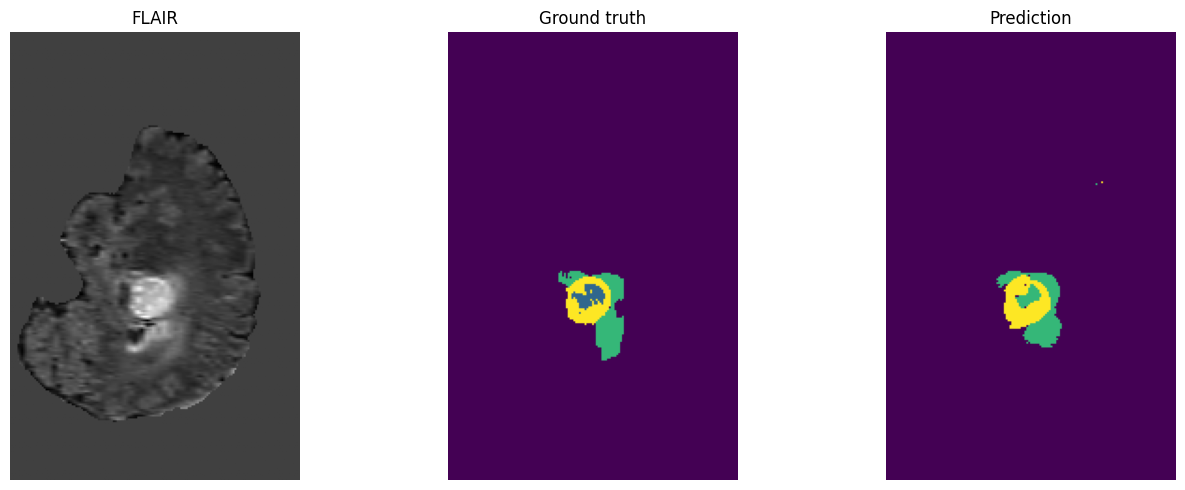

Dice scores: {'WT': 0.8561, 'TC': 0.6285, 'ET': 0.7764}


In [ ]:
# Load best checkpoint
"""
#revist

best_ckpt_path = os.path.join(OUT_DIR, "best.pt")
if os.path.exists(best_ckpt_path):
    ckpt = torch.load(best_ckpt_path, map_location=device)
    model.load_state_dict(ckpt["model_state"])
    print(f"Loaded best checkpoint from epoch {ckpt['epoch']}, Dice={ckpt['best_val_dice']:.4f}")
"""

model = AttentionUNet3D(in_channels=4, out_channels=NUM_CLASSES, base_ch=BASE_CH, depth=DEPTH, deep_supervision=True)

weights_loaded = torch.load("/content/drive/MyDrive/trained models /best.pt", map_location=torch.device('cpu'))

model.load_state_dict(weights_loaded["model_state"])
model.to(device)
model.eval()

sample = val_ds[15]
image, label = sample["image"], sample["label"]

logits = sliding_window_inference(model, image, PATCH_SIZE, NUM_CLASSES, overlap=0.5, device=device)
pred = torch.argmax(logits, dim=0).cpu()

#mid = image.shape[1] // 2
mid = 90
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
axes[0].imshow(image[0, mid], cmap="gray")
axes[0].set_title("FLAIR")
axes[0].axis("off")
axes[1].imshow(label[mid], cmap="viridis", vmin=0, vmax=3)
axes[1].set_title("Ground truth")
axes[1].axis("off")
axes[2].imshow(pred[mid], cmap="viridis", vmin=0, vmax=3)
axes[2].set_title("Prediction")
axes[2].axis("off")
plt.tight_layout()
plt.show()

scores = brats_region_dice(logits.unsqueeze(0), label.unsqueeze(0).to(device))
print("Dice scores:", {k: round(v, 4) for k, v in scores.items()})

### Grad-CAM++ visual explanation



In [ ]:
from scipy import ndimage
from scipy.ndimage import gaussian_filter

class GradCAMPlusPlus3D:
    """
    Grad-CAM++ for a 3D segmentation network.

    Hooks a target conv layer, and on `generate()` computes a class-specific
    (or region-specific) saliency volume showing which input regions drove
    the model's prediction for that class.

    Usage (low level):
        cam = GradCAMPlusPlus3D(model, target_layer=model.up_blocks[-1].conv)
        heatmap = cam.generate(image_patch, target_class=3, region_mask=mask_patch, normalize=False)
        cam.remove_hooks()

    Most of the time, use `explain_class(...)` below, which handles the
    target mask, patch cropping and normalization for you.
    """

    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.activations = None
        self.gradients = None
        self._fwd_handle = target_layer.register_forward_hook(self._save_activation)
        self._bwd_handle = target_layer.register_full_backward_hook(self._save_gradient)

    def _save_activation(self, module, inp, out):
        self.activations = out.detach()

    def _save_gradient(self, module, grad_in, grad_out):
        self.gradients = grad_out[0].detach()

    def remove_hooks(self):
        self._fwd_handle.remove()
        self._bwd_handle.remove()

    def generate(self, image, target_class, region_mask=None, eps=1e-8, normalize=True):
        """
        image:        (C, D, H, W) tensor (no batch dim)
        region_mask:  optional (D, H, W) bool tensor (same spatial size as `image`)
                      restricting the score to those voxels. Default: voxels the
                      model predicts as `target_class`.
        normalize:    True  -> plain min-max to [0, 1] (can be dominated by outliers)
                      False -> return the raw non-negative CAM (normalize it yourself,
                               e.g. with robust_normalize)
        """
        device = next(self.model.parameters()).device
        self.model.zero_grad(set_to_none=True)
        x = image.unsqueeze(0).to(device)

        out = self.model(x)
        logits = out[0] if isinstance(out, tuple) else out  # (1, num_classes, D, H, W)

        if region_mask is None:
            with torch.no_grad():
                pred = torch.argmax(logits, dim=1)[0]
                region_mask = (pred == target_class)
        else:
            region_mask = region_mask.to(device).bool()

        if region_mask.sum() == 0:
            # nothing to explain -> fall back to the whole input
            region_mask = torch.ones_like(region_mask, dtype=torch.bool)

        score = logits[0, target_class][region_mask].sum()
        score.backward()

        A = self.activations[0]   # (K, d, h, w)
        grad = self.gradients[0]  # (K, d, h, w)

        grad2 = grad ** 2
        grad3 = grad ** 3
        sum_A_grad3 = (A * grad3).sum(dim=(1, 2, 3), keepdim=True)
        alpha_denom = 2 * grad2 + sum_A_grad3
        alpha_denom = torch.where(alpha_denom != 0, alpha_denom, torch.ones_like(alpha_denom) * eps)
        alpha = grad2 / alpha_denom

        weights = (alpha * F.relu(grad)).sum(dim=(1, 2, 3))  # (K,)
        cam = F.relu((weights.view(-1, 1, 1, 1) * A).sum(dim=0))  # (d, h, w)

        # upsample to the input size
        cam = cam.unsqueeze(0).unsqueeze(0)
        cam = F.interpolate(cam, size=image.shape[1:], mode="trilinear", align_corners=False)
        cam = cam[0, 0]

        if normalize:
            cam_min, cam_max = cam.min(), cam.max()
            if (cam_max - cam_min) > eps:
                cam = (cam - cam_min) / (cam_max - cam_min)
            else:
                cam = torch.zeros_like(cam)

        return cam.detach().cpu().numpy()


def largest_component(mask_np):
    """Keep only the largest connected component of a boolean 3D mask."""
    lab, n = ndimage.label(mask_np)
    if n <= 1:
        return mask_np.astype(bool)
    sizes = ndimage.sum(mask_np, lab, range(1, n + 1))
    return lab == (int(np.argmax(sizes)) + 1)


def robust_normalize(hm, pct=99.5):
    """Scale a non-negative heatmap to [0, 1] using a high percentile instead of the max,
    so a few extreme voxels cannot flatten the rest of the map."""
    pos = hm[hm > 0]
    if pos.size == 0:
        return np.zeros_like(hm, dtype=np.float32)
    hi = np.percentile(pos, pct)
    return np.clip(hm / (hi + 1e-8), 0, 1).astype(np.float32)


def explain_class(model, image, pred, target_class, target_layer,
                  patch_size=(128, 128, 128), pct=99.5):
    """
    Grad-CAM++ for one class of a 3D segmentation prediction.

    1. target = largest connected component of (pred == target_class)
       (drops stray false-positive voxels)
    2. crop a patch_size patch centred on that component (same input size as training)
    3. run Grad-CAM++ on the patch, with the score restricted to the target voxels
    4. percentile-normalize and paste back into a full-size volume (zeros outside the patch)

    Returns: heatmap (D, H, W) float32 in [0, 1], target_mask (D, H, W) bool
    """
    pred_np = pred.numpy() if torch.is_tensor(pred) else np.asarray(pred)
    mask = largest_component(pred_np == target_class)

    if mask.sum() == 0:
        print(f"No voxels predicted as class {target_class}; nothing to explain.")
        return np.zeros(pred_np.shape, dtype=np.float32), mask

    center = np.argwhere(mask).mean(axis=0).round().astype(int)
    slices = []
    for c, dim, p in zip(center, mask.shape, patch_size):
        start = int(np.clip(c - p // 2, 0, max(dim - p, 0)))
        slices.append(slice(start, min(start + p, dim)))
    slices = tuple(slices)

    img_patch = image[(slice(None),) + slices]
    mask_patch = torch.from_numpy(np.ascontiguousarray(mask[slices]))

    cam = GradCAMPlusPlus3D(model, target_layer)
    try:
        hm_patch = cam.generate(img_patch, target_class, region_mask=mask_patch, normalize=False)
    finally:
        cam.remove_hooks()

    #hm_patch = robust_normalize(hm_patch, pct)
    hm_patch = gaussian_filter(hm_patch, sigma=2)
    heatmap = np.zeros(pred_np.shape, dtype=np.float32)
    heatmap[slices] = hm_patch
    return heatmap, mask


In [ ]:
#emptying gpu cache

import gc
gc.collect()
torch.cuda.empty_cache()

In [ ]:
# Which layer to explain. Finest decoder block = sharpest map but closely mirrors the prediction.
# Try model.up_blocks[-2].conv for a coarser, more semantic explanation.
LAYER = model.up_blocks[-1].conv

TARGET_CLASS = 3  # 0=background, 1=NCR/NET, 2=ED, 3=ET (enhancing tumor)

sample = val_ds[15]
image, label = sample["image"], sample["label"]

# Prediction (sliding-window, same as validation)
with torch.no_grad():
    logits = sliding_window_inference(model, image, PATCH_SIZE, NUM_CLASSES, overlap=0.5, device=device)
    pred = torch.argmax(logits, dim=0).cpu()

# Grad-CAM++ on a tumor-centred patch, with stray voxels removed
heatmap, target_mask = explain_class(model, image, pred, TARGET_CLASS, LAYER, patch_size=PATCH_SIZE)

# --- Sanity checks ---------------------------------------------------------
print("heatmap shape:", heatmap.shape, "| min/max:", heatmap.min(), heatmap.max())
if heatmap.max() > 0:
    z, y, x = np.unravel_index(heatmap.argmax(), heatmap.shape)
    print("peak at (z,y,x):", (int(z), int(y), int(x)), "| predicted class there:", int(pred[z, y, x]))
    print(f"voxels with heat > 0.1: {(heatmap > 0.1).mean() * 100:.3f}% of the volume")
    print(f"mean heat inside target mask: {heatmap[target_mask].mean():.3f}")


heatmap shape: (240, 240, 155) | min/max: 0.0 9292.804
peak at (z,y,x): (139, 158, 73) | predicted class there: 0
voxels with heat > 0.1: 23.458% of the volume
mean heat inside target mask: 6.618


Showing slice: 97


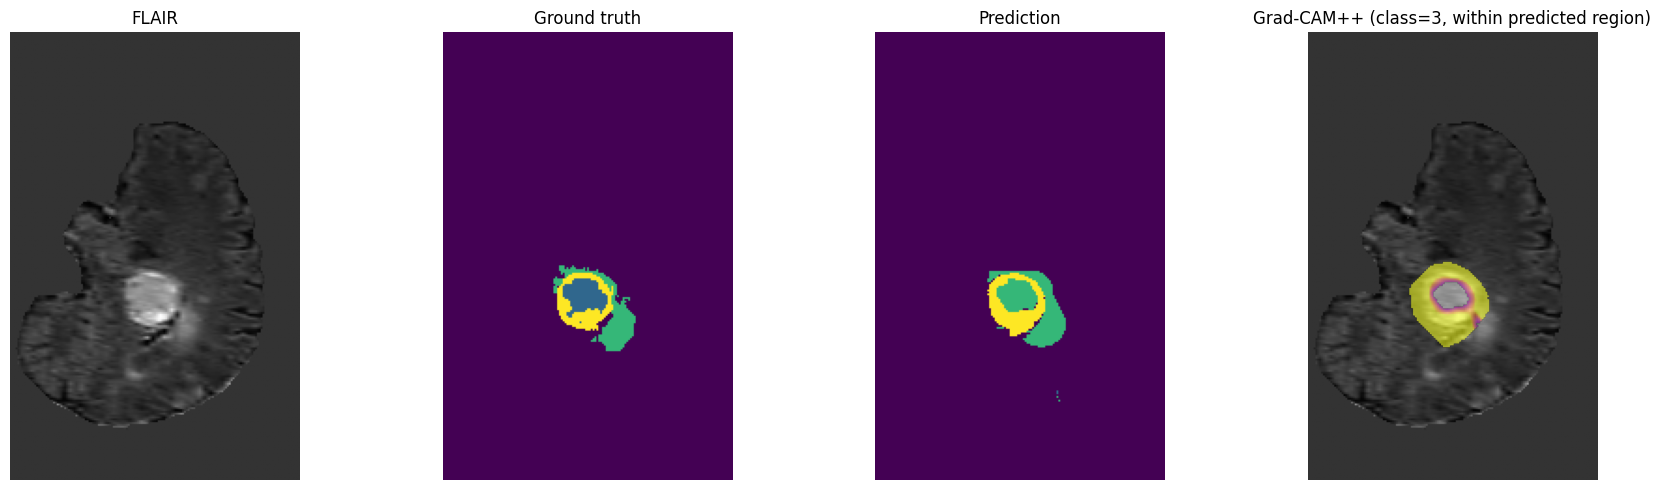

In [ ]:
from scipy.ndimage import binary_dilation

# Pick the slice with the most predicted target-class voxels (falls back to slice 90)
area = target_mask.sum(axis=(1, 2))
mid = int(area.argmax()) if area.max() > 0 else 90
print("Showing slice:", mid)

# Show heat only inside the predicted region plus a small margin
roi = binary_dilation(target_mask, iterations=6)
heat_show = heatmap * roi

fig, axes = plt.subplots(1, 4, figsize=(18, 5))

axes[0].imshow(image[0, mid], cmap="gray")
axes[0].set_title("FLAIR")
axes[0].axis("off")

axes[1].imshow(label[mid], cmap="viridis", vmin=0, vmax=3)
axes[1].set_title("Ground truth")
axes[1].axis("off")

axes[2].imshow(pred[mid], cmap="viridis", vmin=0, vmax=3)
axes[2].set_title("Prediction")
axes[2].axis("off")

axes[3].imshow(image[0, mid], cmap="gray")
axes[3].imshow(np.ma.masked_less(heat_show[mid], 0.3), cmap="plasma", alpha=0.6, vmin=0, vmax=1)
axes[3].set_title(f"Grad-CAM++ (class={TARGET_CLASS}, within predicted region)")
axes[3].axis("off")

plt.tight_layout()
plt.show()

#VLM natural language report

In [ ]:
!pip install -q -U transformers accelerate qwen-vl-utils

from transformers import Qwen2_5_VLForConditionalGeneration, AutoProcessor
from qwen_vl_utils import process_vision_info
import torch
import matplotlib.pyplot as plt
import numpy as np
import os

VLM_MODEL = "Qwen/Qwen2.5-VL-3B-Instruct"

vlm_model = Qwen2_5_VLForConditionalGeneration.from_pretrained(
    VLM_MODEL,
    torch_dtype="auto",
    device_map="auto"
)
vlm_processor = AutoProcessor.from_pretrained(VLM_MODEL)

print("Vision-Language Model loaded successfully!")

Loading weights:   0%|          | 0/824 [00:00<?, ?it/s]

Vision-Language Model loaded successfully!


Selected slice: 99


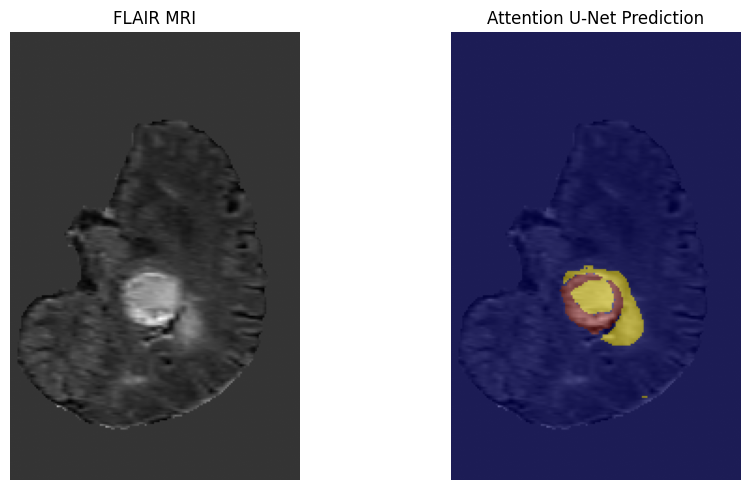

In [ ]:
# --- Prepare prediction for the VLM -----------------------------------
# Uses image / pred from the validation-subject cell above (this notebook
# doesn't have a separate "new patient" inference section, so we reuse
# those instead of the undefined patient_image / patient_pred).

pred_np = pred.detach().cpu().numpy() if torch.is_tensor(pred) else pred
img_t = image  # (C, D, H, W) torch tensor

# Find the slice containing the largest predicted tumor area
tumor_mask = pred_np > 0
slice_areas = tumor_mask.sum(axis=(1, 2))
best_slice = int(np.argmax(slice_areas))
print("Selected slice:", best_slice)

# Create visualization
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].imshow(img_t[0, best_slice].numpy(), cmap="gray")
axes[0].set_title("FLAIR MRI")
axes[0].axis("off")

axes[1].imshow(img_t[0, best_slice].numpy(), cmap="gray")
axes[1].imshow(pred_np[best_slice], cmap="jet", alpha=0.45, vmin=0, vmax=3)
axes[1].set_title("Attention U-Net Prediction")
axes[1].axis("off")

plt.tight_layout()

VLM_IMAGE_PATH = os.path.join(OUT_DIR, "tumor_prediction_for_vlm.png")
plt.savefig(VLM_IMAGE_PATH, dpi=150, bbox_inches="tight")
plt.show()
plt.close()

In [ ]:
# --- Prediction statistics ---------------------------------------------
# NOTE: these are whole-volume counts, not just the displayed slice.
# The prompt below is worded to reflect that distinction.

background_voxels = int(np.sum(pred_np == 0))
ncr_net_voxels = int(np.sum(pred_np == 1))
edema_voxels = int(np.sum(pred_np == 2))
enhancing_voxels = int(np.sum(pred_np == 3))

whole_tumor_voxels = ncr_net_voxels + edema_voxels + enhancing_voxels
tumor_core_voxels = ncr_net_voxels + enhancing_voxels

print("Prediction statistics (whole volume)")
print("-------------------------------------")
print("NCR/NET:", ncr_net_voxels)
print("Edema:", edema_voxels)
print("Enhancing tumor:", enhancing_voxels)
print("Whole tumor:", whole_tumor_voxels)
print("Tumor core:", tumor_core_voxels)

Prediction statistics (whole volume)
-------------------------------------
NCR/NET: 33
Edema: 20291
Enhancing tumor: 13344
Whole tumor: 33668
Tumor core: 13377


In [ ]:
# --- Generate textual explanation with the VLM -------------------------

prompt = f"""
You are a medical imaging AI assistant.

You are given one representative MRI slice together with the tumor
segmentation prediction produced by a 3D Attention U-Net model. The
voxel statistics below are computed over the FULL 3D volume, not just
this single slice — use them to describe overall composition, and use
the image itself to describe what is visible in this slice.

The segmentation classes are:

Class 0 = Background
Class 1 = NCR/NET
Class 2 = Edema
Class 3 = Enhancing Tumor

Whole-volume prediction statistics:

NCR/NET voxels: {ncr_net_voxels}
Edema voxels: {edema_voxels}
Enhancing tumor voxels: {enhancing_voxels}
Whole tumor voxels: {whole_tumor_voxels}
Tumor core voxels: {tumor_core_voxels}

Generate a concise textual representation of the model prediction.

Describe:
1. Whether a tumor region is present in the prediction.
2. The major segmented tumor components.
3. The relative contribution of edema, tumor core and enhancing tumor
   (based on the volume-wide statistics).
4. The general appearance and spatial distribution visible in the
   provided slice specifically.

Do NOT diagnose the patient.
Do NOT predict tumor grade.
Do NOT recommend treatment.
Do NOT infer information that is not visible in the image or provided statistics.

The output should be a short, clear paragraph suitable for explaining
a machine-learning segmentation result.
"""

messages = [
    {
        "role": "user",
        "content": [
            {"type": "image", "image": f"file://{VLM_IMAGE_PATH}"},
            {"type": "text", "text": prompt},
        ],
    }
]

text = vlm_processor.apply_chat_template(
    messages, tokenize=False, add_generation_prompt=True
)
image_inputs, video_inputs = process_vision_info(messages)

inputs = vlm_processor(
    text=[text],
    images=image_inputs,
    videos=video_inputs,
    padding=True,
    return_tensors="pt",
).to(vlm_model.device)

with torch.no_grad():
    generated_ids = vlm_model.generate(**inputs, max_new_tokens=200)

generated_ids_trimmed = [
    out_ids[len(in_ids):]
    for in_ids, out_ids in zip(inputs.input_ids, generated_ids)
]

textual_representation = vlm_processor.batch_decode(
    generated_ids_trimmed, skip_special_tokens=True, clean_up_tokenization_spaces=False
)[0]

print("\nTEXTUAL REPRESENTATION")
print("=" * 70)
print(textual_representation)


TEXTUAL REPRESENTATION
The 3D Attention U-Net model has predicted a tumor region in the FLAIR MRI slice. The tumor appears to have an enhancing component, as indicated by the yellow area in the right image. The tumor core, which is the central part of the tumor, occupies approximately 39% of the whole tumor volume based on the statistics. The majority of the tumor volume is composed of edema, making up about 61% of the total tumor volume. The background and non-cancerous regions (NCR/NET) account for a small portion of the volume. The spatial distribution shows the tumor predominantly occupying the right hemisphere of the brain, with the enhancing tumor component more concentrated towards the center.
